RECIPE PENGOLAHAN DATA CURAH HUJAN TANA TORAJA
Periode: 2015 - 2025
Jumlah baris data: 12
Jumlah data kosong: 0

PREVIEW DATA:
    Bulan   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025
  Januari  239.5  239.5  102.0  189.5  180.5  319.8  404.1  206.0  148.6  428.8  274.4
 Februari  331.0  331.0  168.0  241.8  310.3  482.3  235.3  254.6  121.8  438.9  225.9
    Maret  319.3  319.3  148.0  316.9  310.1  462.7  502.8  273.3  414.8  326.1  241.2
    April  598.5  598.5  188.0  253.4  398.2  669.9  262.3  394.5  364.9  641.0  379.2
      Mei  219.3  219.3  134.0  168.0  132.1  370.4  247.2  281.1  213.3  250.8  262.7
     Juni  148.0  148.0  116.0  312.8  230.6  220.3   73.3  158.5  154.3  114.1  262.6
     Juli   22.0   22.0   69.0   86.7   15.8  161.5  150.1  165.2   75.9  158.0   65.2
  Agustus   20.6   20.6   52.0  123.0   17.2  106.3  161.7  248.4   41.3   71.8  105.0
September    0.8    0.8   33.0   22.8    9.3  125.1  220.5  103.8   18.4   63.8   92.1
  O

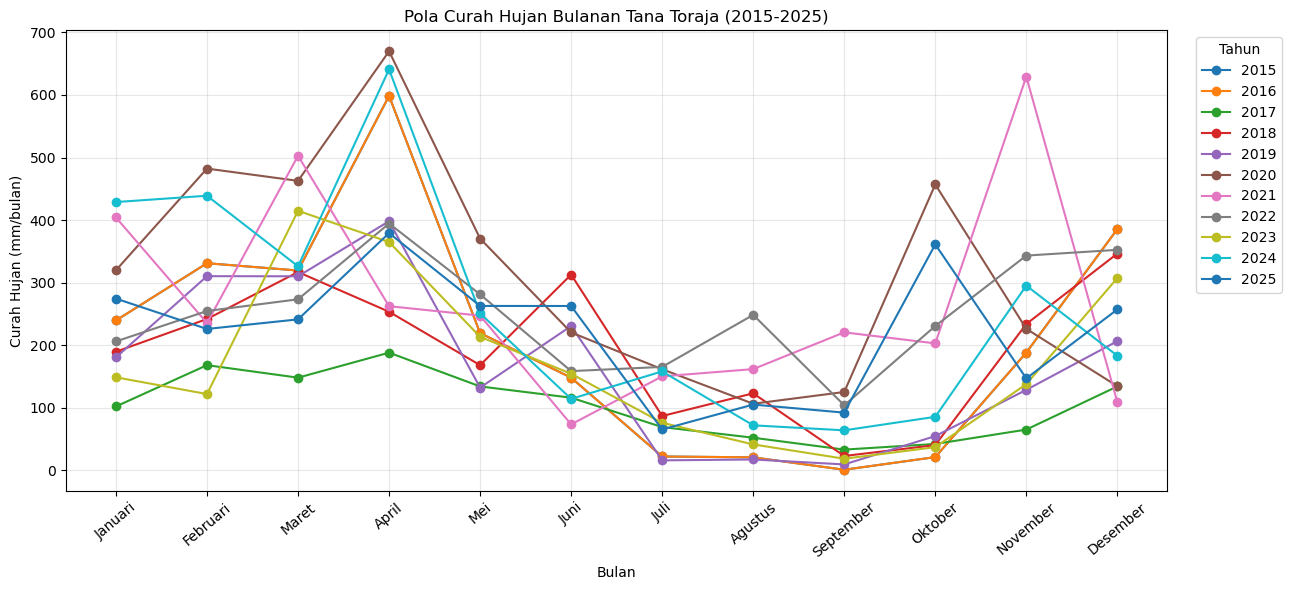

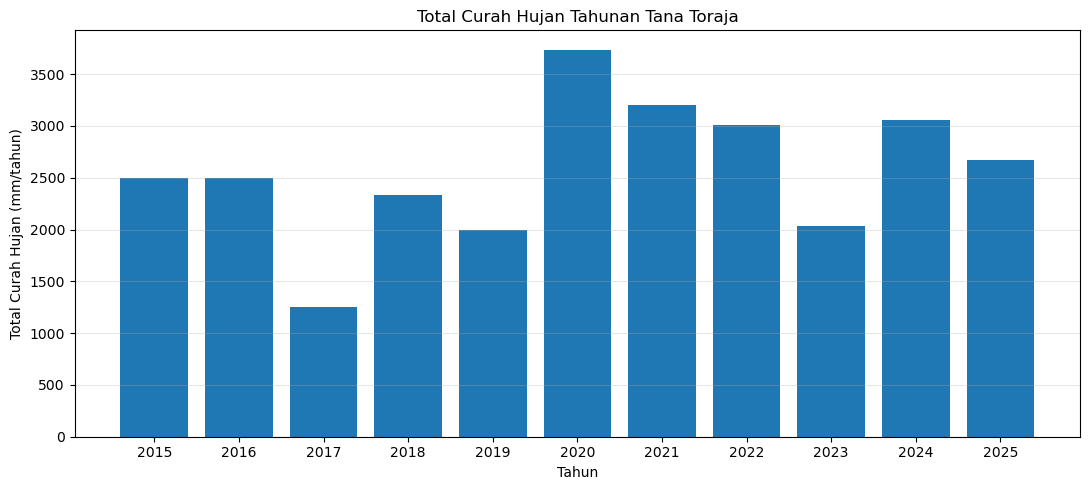

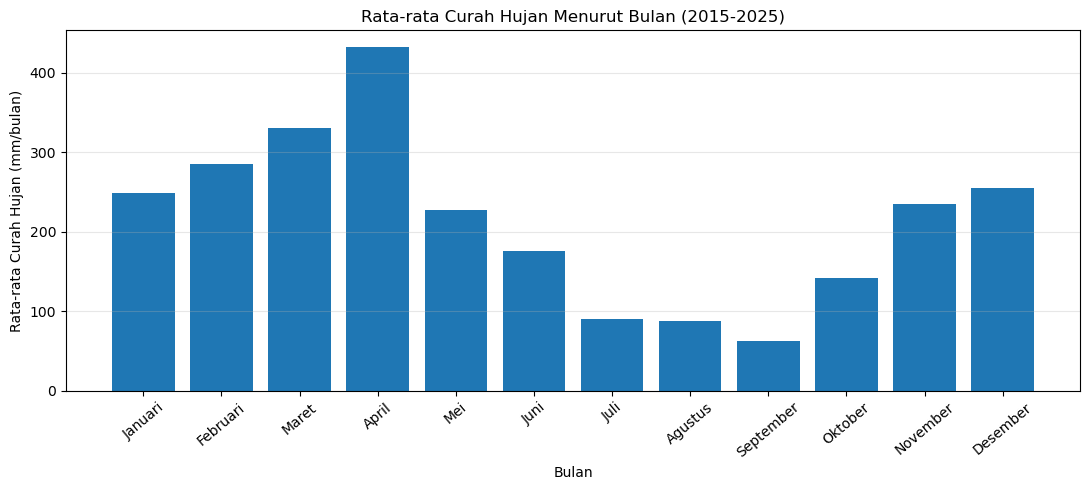

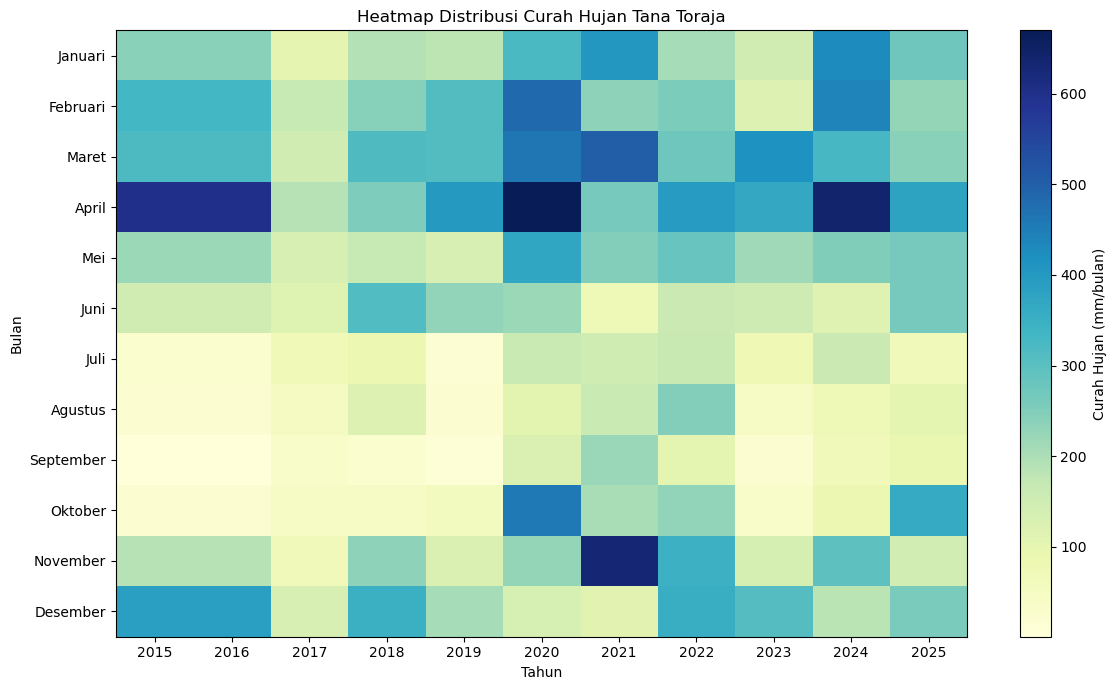


RINGKASAN POLA BULANAN
Rata-rata tertinggi: April - 431.67 mm/bulan
Rata-rata terendah: September - 62.76 mm/bulan

RINGKASAN TAHUNAN
Total tertinggi: 2020 - 3735.7 mm/tahun
Total terendah: 2017 - 1251.0 mm/tahun

PENGOLAHAN DATA SELESAI
Folder output: C:\Users\HP\Downloads\hasil_analisis_curah_hujan
File hasil:
- 01_pola_curah_hujan_bulanan.png
- 02_total_curah_hujan_tahunan.png
- 03_rata_rata_curah_hujan_bulanan.png
- 04_heatmap_curah_hujan.png
- data_curah_hujan_bersih.csv
- data_curah_hujan_format_panjang.csv
- laporan_analisis_curah_hujan.xlsx


In [8]:

# ============================================================
# RECIPE: RAINFALL DATA PROCESSING AND ANALYSIS
# Data: Curah Hujan Tana Toraja, 2015-2025
# Output: Tabel statistik, grafik, heatmap, dan laporan Excel
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. MEMBACA DATA EXCEL
# ------------------------------------------------------------

FILE_INPUT = Path(
    r"C:\Users\HP\Downloads\curah hujan tana toraja.xlsx"
)

OUTPUT_DIR = Path(
    r"C:\Users\HP\Downloads\hasil_analisis_curah_hujan"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not FILE_INPUT.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {FILE_INPUT}\n"
        "Periksa kembali lokasi file Excel."
    )

df = pd.read_excel(FILE_INPUT)

# Membersihkan nama kolom
df.columns = [str(c).strip() for c in df.columns]

if "Bulan" not in df.columns:
    raise ValueError(
        f"Kolom 'Bulan' tidak ditemukan. Kolom tersedia: {df.columns.tolist()}"
    )

# Menormalkan nama kolom tahun, termasuk header seperti 2025.0
kolom_tahun = {}
for kolom in df.columns:
    try:
        angka = float(kolom)
        if angka.is_integer() and 1900 <= angka <= 2100:
            kolom_tahun[kolom] = int(angka)
    except (ValueError, TypeError):
        pass

if not kolom_tahun:
    raise ValueError("Kolom tahun tidak ditemukan dalam file Excel.")

df = df.rename(columns=kolom_tahun)
tahun_list = sorted(set(kolom_tahun.values()))

# ------------------------------------------------------------
# 2. PEMBERSIHAN DATA
# ------------------------------------------------------------

daftar_bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli", "Agustus",
    "September", "Oktober", "November", "Desember"
]

df["Bulan"] = (
    df["Bulan"].astype("string").str.strip().str.title()
)

# Menangani variasi penulisan nama bulan
alias_bulan = {
    "January": "Januari",
    "February": "Februari",
    "March": "Maret",
    "May": "Mei",
    "June": "Juni",
    "July": "Juli",
    "August": "Agustus",
    "October": "Oktober",
    "December": "Desember"
}
df["Bulan"] = df["Bulan"].replace(alias_bulan)

for tahun in tahun_list:
    # Mengubah angka desimal dengan koma menjadi angka
    nilai = (
        df[tahun].astype("string").str.strip()
        .str.replace(",", ".", regex=False)
    )
    df[tahun] = pd.to_numeric(nilai, errors="coerce")

df = df[df["Bulan"].isin(daftar_bulan)].copy()

df["Bulan"] = pd.Categorical(
    df["Bulan"],
    categories=daftar_bulan,
    ordered=True
)

df = df.sort_values("Bulan").reset_index(drop=True)

# Nilai negatif ditandai sebagai tidak valid
for tahun in tahun_list:
    df.loc[df[tahun] < 0, tahun] = np.nan

# Format panjang: satu baris untuk setiap kombinasi bulan-tahun
data_panjang = df.melt(
    id_vars=["Bulan"],
    value_vars=tahun_list,
    var_name="Tahun",
    value_name="Curah_Hujan_mm"
)

data_panjang["Tahun"] = data_panjang["Tahun"].astype(int)

print("=" * 65)
print("RECIPE PENGOLAHAN DATA CURAH HUJAN TANA TORAJA")
print("=" * 65)
print("Periode:", min(tahun_list), "-", max(tahun_list))
print("Jumlah baris data:", len(df))
print("Jumlah data kosong:", data_panjang["Curah_Hujan_mm"].isna().sum())
print("\nPREVIEW DATA:")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 3. STATISTIK CURAH HUJAN PER TAHUN
# ------------------------------------------------------------

statistik_tahunan = data_panjang.groupby(
    "Tahun", observed=True
)["Curah_Hujan_mm"].agg(
    Jumlah_Bulan_Tersedia="count",
    Rata_Rata_Bulanan="mean",
    Median_Bulanan="median",
    Minimum_Bulanan="min",
    Maksimum_Bulanan="max",
    Standar_Deviasi="std"
)

# Total tahunan hanya dihitung jika 12 bulan tersedia
total = data_panjang.groupby(
    "Tahun", observed=True
)["Curah_Hujan_mm"].sum(min_count=1)

jumlah = data_panjang.groupby(
    "Tahun", observed=True
)["Curah_Hujan_mm"].count()

statistik_tahunan["Total_Tahunan_mm"] = total.where(jumlah == 12)

statistik_tahunan = statistik_tahunan.round(2)

print("\nSTATISTIK CURAH HUJAN TAHUNAN")
print(statistik_tahunan.to_string())

# ------------------------------------------------------------
# 4. STATISTIK CURAH HUJAN PER BULAN
# ------------------------------------------------------------

statistik_bulanan = data_panjang.groupby(
    "Bulan", observed=True
)["Curah_Hujan_mm"].agg(
    Rata_Rata="mean",
    Median="median",
    Minimum="min",
    Maksimum="max",
    Standar_Deviasi="std",
    Jumlah_Data="count"
).reindex(daftar_bulan).round(2)

print("\nSTATISTIK CURAH HUJAN BULANAN")
print(statistik_bulanan.to_string())

# ------------------------------------------------------------
# 5. GRAFIK POLA CURAH HUJAN BULANAN PER TAHUN
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

for tahun in tahun_list:
    kelompok = data_panjang[
        data_panjang["Tahun"] == tahun
    ]

    ax.plot(
        kelompok["Bulan"].astype(str),
        kelompok["Curah_Hujan_mm"],
        marker="o",
        linewidth=1.5,
        label=str(tahun)
    )

ax.set_title("Pola Curah Hujan Bulanan Tana Toraja (2015-2025)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Curah Hujan (mm/bulan)")
ax.tick_params(axis="x", rotation=40)
ax.grid(True, alpha=0.3)
ax.legend(title="Tahun", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "01_pola_curah_hujan_bulanan.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. GRAFIK TOTAL CURAH HUJAN TAHUNAN
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

total_valid = statistik_tahunan["Total_Tahunan_mm"].dropna()

ax.bar(
    total_valid.index.astype(str),
    total_valid.values
)

ax.set_title("Total Curah Hujan Tahunan Tana Toraja")
ax.set_xlabel("Tahun")
ax.set_ylabel("Total Curah Hujan (mm/tahun)")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "02_total_curah_hujan_tahunan.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. GRAFIK RATA-RATA CURAH HUJAN BULANAN
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    statistik_bulanan.index.astype(str),
    statistik_bulanan["Rata_Rata"].values
)

ax.set_title("Rata-rata Curah Hujan Menurut Bulan (2015-2025)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-rata Curah Hujan (mm/bulan)")
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "03_rata_rata_curah_hujan_bulanan.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. HEATMAP DISTRIBUSI CURAH HUJAN BULANAN DAN TAHUNAN
# ------------------------------------------------------------

matriks = df.set_index("Bulan")[tahun_list].copy()

fig, ax = plt.subplots(figsize=(12, 7))

peta = ax.imshow(
    matriks.to_numpy(dtype=float),
    aspect="auto",
    interpolation="nearest",
    cmap="YlGnBu"
)

ax.set_xticks(range(len(tahun_list)))
ax.set_xticklabels([str(t) for t in tahun_list])
ax.set_yticks(range(len(daftar_bulan)))
ax.set_yticklabels(daftar_bulan)

ax.set_title("Heatmap Distribusi Curah Hujan Tana Toraja")
ax.set_xlabel("Tahun")
ax.set_ylabel("Bulan")

cbar = fig.colorbar(peta, ax=ax)
cbar.set_label("Curah Hujan (mm/bulan)")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "04_heatmap_curah_hujan.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. MENENTUKAN BULAN TERBASAH DAN TERKERING
# ------------------------------------------------------------

rata_valid = statistik_bulanan["Rata_Rata"].dropna()

if not rata_valid.empty:
    bulan_terbasah = rata_valid.idxmax()
    bulan_terkering = rata_valid.idxmin()

    print("\nRINGKASAN POLA BULANAN")
    print("Rata-rata tertinggi:",
          bulan_terbasah, "-", rata_valid.max(), "mm/bulan")
    print("Rata-rata terendah:",
          bulan_terkering, "-", rata_valid.min(), "mm/bulan")

# Tahun dengan total tertinggi dan terendah
if not total_valid.empty:
    print("\nRINGKASAN TAHUNAN")
    print(
        "Total tertinggi:",
        int(total_valid.idxmax()),
        "-", total_valid.max(), "mm/tahun"
    )
    print(
        "Total terendah:",
        int(total_valid.idxmin()),
        "-", total_valid.min(), "mm/tahun"
    )

# ------------------------------------------------------------
# 10. MENYIMPAN TABEL KE CSV DAN EXCEL
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_DIR / "data_curah_hujan_bersih.csv",
    index=False
)

data_panjang.to_csv(
    OUTPUT_DIR / "data_curah_hujan_format_panjang.csv",
    index=False
)

with pd.ExcelWriter(
    OUTPUT_DIR / "laporan_analisis_curah_hujan.xlsx",
    engine="openpyxl"
) as writer:
    df.to_excel(
        writer, sheet_name="Data_Bersih", index=False
    )
    data_panjang.to_excel(
        writer, sheet_name="Data_Panjang", index=False
    )
    statistik_tahunan.to_excel(
        writer, sheet_name="Statistik_Tahunan"
    )
    statistik_bulanan.to_excel(
        writer, sheet_name="Statistik_Bulanan"
    )

# ------------------------------------------------------------
# 11. RINGKASAN HASIL
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PENGOLAHAN DATA SELESAI")
print("=" * 65)
print("Folder output:", OUTPUT_DIR.resolve())
print("File hasil:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name)
